# 10 · Economics and Econometrics

Economists use Python to test theories against data and to forecast. **statsmodels** provides the
econometric toolkit (regression with proper standard errors, time-series models, statistical tests) on
top of pandas. This module works with fifty years of US macroeconomic data.

**You will learn**
1. Turning levels into growth rates and handling quarterly dates
2. Testing an economic law with regression: Okun's law (output and unemployment)
3. Reading a regression honestly: coefficients, confidence intervals, robust standard errors, residual checks
4. Forecasting GDP growth with an ARIMA model, and checking it against naive forecasts with a proper backtest

## 1. The data
`macrodata` ships with statsmodels: US quarterly series from 1959 to 2009, including real GDP, the
unemployment rate, inflation and interest rates.

In [1]:
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

raw = sm.datasets.macrodata.load_pandas().data
raw.index = pd.PeriodIndex.from_fields(year=raw["year"].astype(int), quarter=raw["quarter"].astype(int), freq="Q")
print(sm.datasets.macrodata.NOTE.split("Number of Variables")[0].strip()[:400])
raw[["realgdp", "unemp", "infl", "tbilrate"]].tail()

::
    Number of Observations - 203


,realgdp,unemp,infl,tbilrate
2008Q3,13324.600,6.0,-3.16,1.17
2008Q4,13141.920,6.9,-8.79,0.12
2009Q1,12925.410,8.1,0.94,0.22
2009Q2,12901.504,9.2,3.37,0.18
2009Q3,12990.341,9.6,3.56,0.12


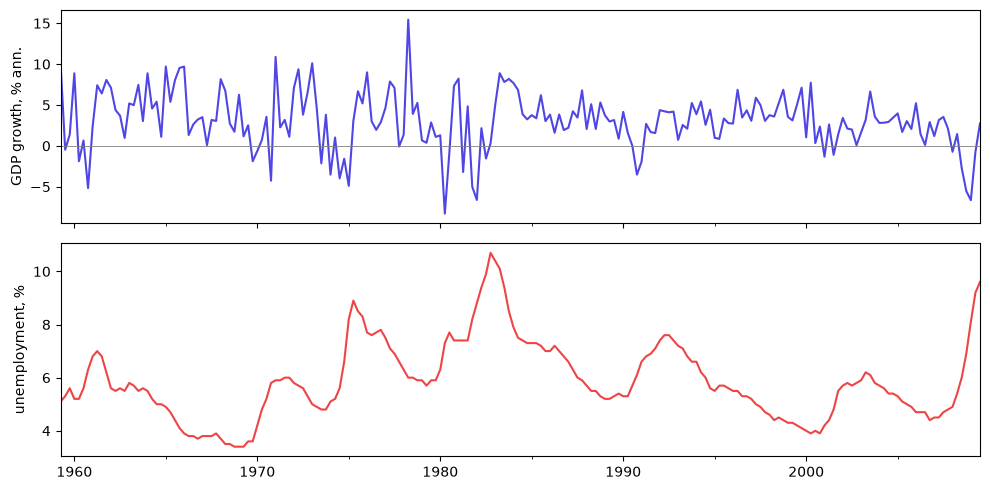

,gdp_growth,unemp,d_unemp,infl
count,202.00,202.00,202.00,202.00
mean,3.10,5.89,0.02,3.98
std,3.52,1.46,0.34,3.25
min,-8.28,3.40,-0.90,-8.79
25%,1.34,4.90,-0.20,2.28
50%,3.06,5.65,0.00,3.24
75%,5.09,6.80,0.10,4.98
max,15.43,10.70,1.60,14.62


In [2]:
df = pd.DataFrame({
    "gdp_growth": 400 * np.log(raw["realgdp"]).diff(),     # annualised % growth (log difference)
    "unemp": raw["unemp"],
    "d_unemp": raw["unemp"].diff(),                        # change in the unemployment rate, points
    "infl": raw["infl"],
}).dropna()

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
df["gdp_growth"].plot(ax=ax[0], color="#4f46e5"); ax[0].axhline(0, color="grey", lw=.6); ax[0].set_ylabel("GDP growth, % ann.")
df["unemp"].plot(ax=ax[1], color="#ef4444"); ax[1].set_ylabel("unemployment, %")
plt.tight_layout(); plt.show()
df.describe().round(2)

## 2. Okun's law
Arthur Okun observed in 1962 that when output grows faster than its normal pace, unemployment falls.
In regression form: $\Delta u_t = \alpha + \beta\, g_t + \varepsilon_t$, where $g_t$ is GDP growth. Okun's
"rule of thumb" expects $\beta$ around $-0.3$ to $-0.5$ (per year), and $-\alpha/\beta$ is the growth rate
that keeps unemployment stable.

In [3]:
X = sm.add_constant(df["gdp_growth"])
okun = sm.OLS(df["d_unemp"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})   # robust to autocorrelation
print(okun.summary().tables[1])
alpha, beta = okun.params
print(f"\nR² = {okun.rsquared:.2f}. Each extra point of annualised growth lowers unemployment by "
      f"{-beta:.3f} points per quarter (~{-4 * beta:.2f} per year).")
print(f"Growth needed just to keep unemployment stable: {-alpha / beta:.1f}% a year.")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2271      0.042      5.467      0.000       0.146       0.309
gdp_growth    -0.0671      0.009     -7.788      0.000      -0.084      -0.050

R² = 0.47. Each extra point of annualised growth lowers unemployment by 0.067 points per quarter (~0.27 per year).
Growth needed just to keep unemployment stable: 3.4% a year.


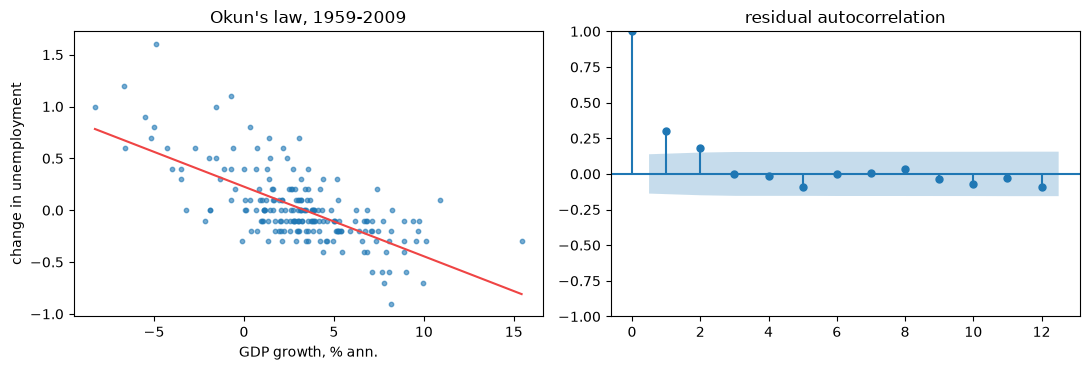

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].scatter(df["gdp_growth"], df["d_unemp"], s=10, alpha=.6)
xs = np.linspace(df["gdp_growth"].min(), df["gdp_growth"].max(), 50)
ax[0].plot(xs, alpha + beta * xs, color="#ef4444"); ax[0].set_xlabel("GDP growth, % ann."); ax[0].set_ylabel("change in unemployment")
ax[0].set_title("Okun's law, 1959-2009")
resid = okun.resid
sm.graphics.tsa.plot_acf(resid, lags=12, ax=ax[1]); ax[1].set_title("residual autocorrelation")
plt.tight_layout(); plt.show()

The relationship is strong and the sign is exactly what theory predicts. The residuals are autocorrelated
(unemployment adjusts over several quarters), which is why the standard errors above are HAC
(heteroskedasticity- and autocorrelation-consistent): ordinary errors would overstate the precision.

**Is the law stable over time?** A quick check: estimate it on each decade separately.

In [5]:
rows = []
for start in range(1960, 2010, 10):
    d = df[(df.index.year >= start) & (df.index.year < start + 10)]
    fit = sm.OLS(d["d_unemp"], sm.add_constant(d["gdp_growth"])).fit()
    lo, hi = fit.conf_int().loc["gdp_growth"]
    rows.append(dict(decade=f"{start}s", beta=fit.params["gdp_growth"], ci_low=lo, ci_high=hi, quarters=len(d)))
pd.DataFrame(rows).set_index("decade").round(3)

,beta,ci_low,ci_high,quarters
decade,,,,
1960s,-0.045,-0.064,-0.026,40
1970s,-0.060,-0.084,-0.035,40
1980s,-0.083,-0.103,-0.063,40
1990s,-0.050,-0.076,-0.024,40
2000s,-0.094,-0.124,-0.063,39


## 3. Forecasting GDP growth
An ARIMA model predicts a series from its own past. To know whether it is any good, we compare it with
two naive forecasts in a **rolling-origin backtest**: at each quarter from 1990 on, fit on the past only,
forecast the next quarter, then move forward.

In [6]:
import warnings
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings("ignore")

y = df["gdp_growth"].astype(float).reset_index(drop=True)
dates = df.index
start = int(np.where(dates.year == 1990)[0][0])
preds = {"ARIMA(1,0,1)": [], "historical mean": [], "last value": []}
actual = []
for t in range(start, len(y)):
    past = y.iloc[:t]
    preds["ARIMA(1,0,1)"].append(ARIMA(past, order=(1, 0, 1)).fit().forecast(1).iloc[0])
    preds["historical mean"].append(past.mean())
    preds["last value"].append(past.iloc[-1])
    actual.append(y.iloc[t])
actual = np.array(actual)
scores = pd.DataFrame({k: {"MAE": np.mean(np.abs(np.array(v) - actual)), "RMSE": np.sqrt(np.mean((np.array(v) - actual) ** 2))}
                       for k, v in preds.items()}).T.round(3)
print(f"{len(actual)} one-quarter-ahead forecasts, 1990-2009")
scores

79 one-quarter-ahead forecasts, 1990-2009


,MAE,RMSE
"ARIMA(1,0,1)",1.739,2.347
historical mean,1.892,2.691
last value,2.132,2.654


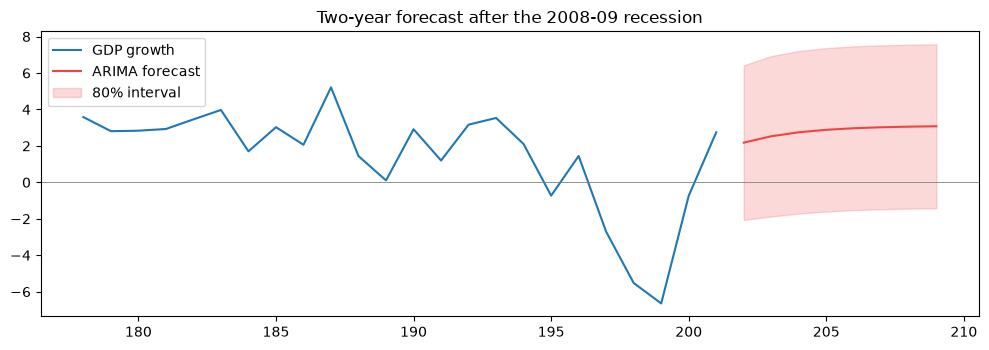

In [7]:
fit = ARIMA(y, order=(1, 0, 1)).fit()
fc = fit.get_forecast(8)
ci = fc.conf_int(alpha=0.2)
hist = y.iloc[-24:]
plt.figure(figsize=(10, 3.6))
plt.plot(range(len(y) - 24, len(y)), hist, label="GDP growth")
fx = range(len(y), len(y) + 8)
plt.plot(fx, fc.predicted_mean, color="#ef4444", label="ARIMA forecast")
plt.fill_between(fx, ci.iloc[:, 0], ci.iloc[:, 1], color="#ef4444", alpha=.2, label="80% interval")
plt.axhline(0, color="grey", lw=.6); plt.legend(); plt.title("Two-year forecast after the 2008-09 recession"); plt.tight_layout(); plt.show()

**Reading it honestly.** ARIMA beats "repeat the last quarter", but only modestly beats the historical
mean: quarterly GDP growth is close to unpredictable from its own past. The forecast after 2009 reverts
to the average within a few quarters and the interval is wide. Serious macro forecasting adds other
information (surveys, financial markets, leading indicators), which is exactly what multivariate models
such as VARs and dynamic factor models in statsmodels are for.

## Libraries worth knowing
| Area | Libraries |
|---|---|
| econometrics, time series | statsmodels, linearmodels (panel data, instrumental variables), arch (volatility) |
| forecasting | statsmodels, sktime, Darts, Prophet |
| causal inference | DoWhy, EconML, DoubleML |
| economic data | pandas-datareader, fredapi (Federal Reserve data), wbgapi (World Bank), sdmx1 (statistical agencies) |
| quantitative finance | QuantLib, PyPortfolioOpt, vectorbt |

## Exercises
1. Estimate a Phillips curve: regress the change in inflation on the unemployment rate. Is it stable across decades?
2. Add lagged GDP growth to the Okun regression (`df["gdp_growth"].shift(1)`). Does R² improve?
3. Extend the backtest to forecasts four quarters ahead. Does ARIMA still beat the mean?